# 03 - Synthetic Control
**Owner:** Member 2 (Dhananjay) · **Week 2**

**Question:** how much extra revenue did North's price rise (from 1 May 2025) cause?

**Idea:** South and West never changed price. We find the mix of South and West that best copies North's revenue *before* 1 May. That mix is "synthetic North": our estimate of what North would have earned without the price change. After 1 May, the gap between real and synthetic North is the effect.

## Part 1 - Reshape the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

df = pd.read_csv("project1_algorithmic_pricing_synthetic_dataset.csv", parse_dates=["date"])

# One row per date, one revenue column per region
revenue = df.pivot(index="date", columns="region", values="revenue")
TREATMENT_DATE = pd.Timestamp("2025-05-01")
TREATED = "North"
DONORS = ["South", "West"]

print(revenue.shape)
revenue.head()

(180, 3)


region,North,South,West
date,,,
2025-01-01,50651.59,48937.65,60109.02
2025-01-02,54431.06,52101.37,62082.51
2025-01-03,62516.51,53274.36,57028.24
2025-01-04,67241.10,60980.94,65800.24
2025-01-05,66825.20,66908.57,69358.06


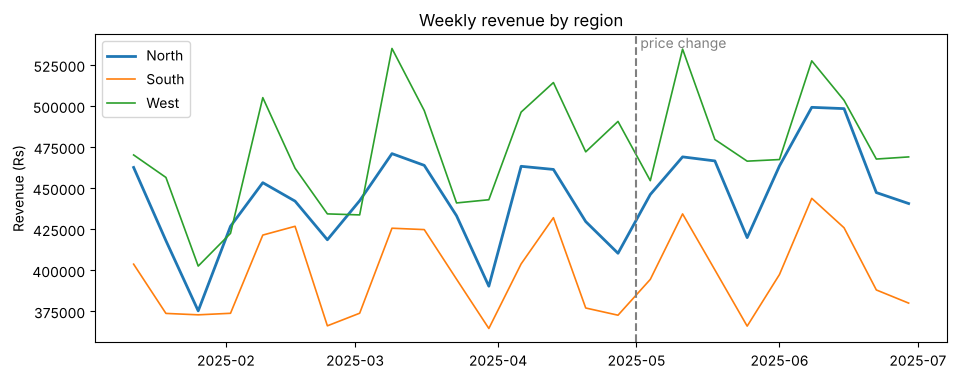

In [2]:
# Weekly totals smooth out day-to-day noise
weekly = revenue.resample("W-SUN").sum()
weekly = weekly[revenue.resample("W-SUN").size() == 7]   # keep full weeks only

fig, ax = plt.subplots(figsize=(11, 4))
for region in revenue.columns:
    ax.plot(weekly.index, weekly[region], label=region, linewidth=2 if region == TREATED else 1.2)
ax.axvline(TREATMENT_DATE, color="grey", linestyle="--")
ax.text(TREATMENT_DATE, ax.get_ylim()[1], " price change", va="top", color="grey")
ax.set_title("Weekly revenue by region")
ax.set_ylabel("Revenue (Rs)")
ax.legend()
plt.show()

## Part 2 - Find the donor weights
Weights must be between 0 and 1 and add up to 1, so synthetic North is a genuine blend of South and West. We pick the weights that make the pre-period gap as small as possible.

In [3]:
def fit_weights(data):
    pre = data.index < TREATMENT_DATE
    X = data.loc[pre, DONORS].values     # donor revenue before May
    y = data.loc[pre, TREATED].values    # North revenue before May

    scale = y.mean()                     # rescale so the optimiser works with numbers near 1

    def pre_period_error(w):
        return np.mean(((y - X @ w) / scale) ** 2)

    result = minimize(
        pre_period_error,
        x0=np.full(len(DONORS), 1 / len(DONORS)),
        bounds=[(0, 1)] * len(DONORS),
        constraints={"type": "eq", "fun": lambda w: w.sum() - 1},
    )
    return pd.Series(result.x, index=DONORS)

weights_daily = fit_weights(revenue)
print("Donor weights (daily data):")
print(weights_daily.round(3))
# Sanity check: weights must add up to 1
print("Sum of weights:", round(weights_daily.sum(), 3))

Donor weights (daily data):
South    0.522
West     0.478
dtype: float64
Sum of weights: 1.0


## Part 3 - Build synthetic North (pre-period fit)

In [4]:
def build_synthetic(data, weights):
    out = pd.DataFrame(index=data.index)
    out["actual"] = data[TREATED]
    out["synthetic"] = data[DONORS] @ weights
    out["gap"] = out["actual"] - out["synthetic"]
    out["post"] = out.index >= TREATMENT_DATE
    return out

synth_daily = build_synthetic(revenue, weights_daily)

pre = synth_daily[~synth_daily["post"]]
rmse = np.sqrt((pre["gap"] ** 2).mean())
print(f"Pre-period fit error (RMSE): Rs {rmse:,.0f} per day, "
      f"{rmse / pre['actual'].mean():.1%} of North's average daily revenue")

Pre-period fit error (RMSE): Rs 6,046 per day, 9.8% of North's average daily revenue


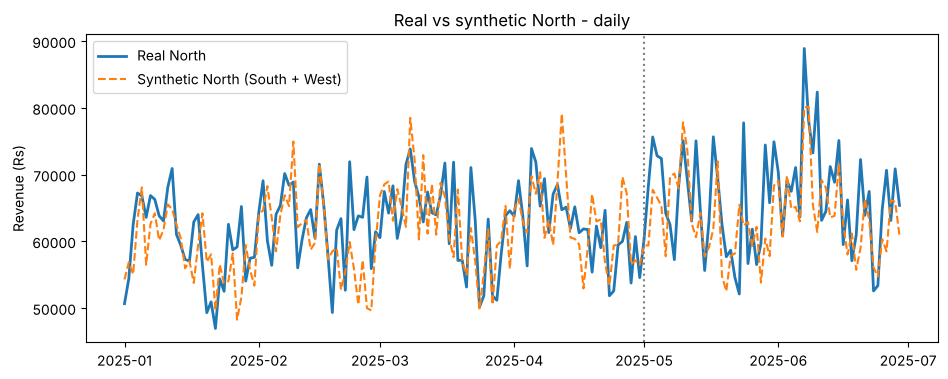

In [5]:
def plot_synthetic(s, title):
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(s.index, s["actual"], label="Real North", linewidth=2)
    ax.plot(s.index, s["synthetic"], label="Synthetic North (South + West)", linestyle="--")
    ax.axvline(TREATMENT_DATE, color="grey", linestyle=":")
    ax.set_title(title)
    ax.set_ylabel("Revenue (Rs)")
    ax.legend()
    plt.show()

plot_synthetic(synth_daily, "Real vs synthetic North - daily")

## Part 4 - Effect after the price change

In [6]:
def effect_summary(s, label):
    post = s[s["post"]]
    avg_gap = post["gap"].mean()
    pct = avg_gap / post["synthetic"].mean()
    return pd.Series({"data": label,
                      "avg extra revenue per period (Rs)": round(avg_gap),
                      "lift (%)": round(pct * 100, 1),
                      "total extra revenue (Rs)": round(post["gap"].sum())})

daily_result = effect_summary(synth_daily, "daily")
daily_result

data                                  daily
avg extra revenue per period (Rs)      2798
lift (%)                                4.4
total extra revenue (Rs)             167866
dtype: object

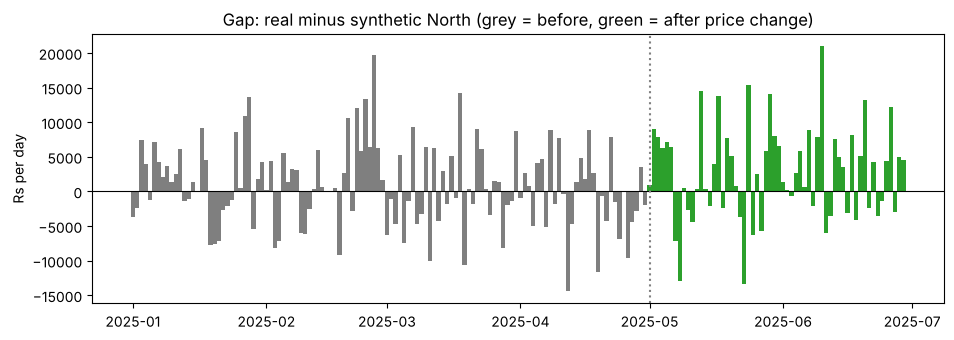

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(synth_daily.index, synth_daily["gap"],
       color=np.where(synth_daily["post"], "tab:green", "tab:grey"), width=1)
ax.axhline(0, color="black", linewidth=0.8)
ax.axvline(TREATMENT_DATE, color="grey", linestyle=":")
ax.set_title("Gap: real minus synthetic North (grey = before, green = after price change)")
ax.set_ylabel("Rs per day")
plt.show()

## Part 5 - Weekly version (smoother fit)
Daily revenue swings a lot, which makes the fit noisy. Repeating on weekly totals checks whether the answer holds.

Donor weights (weekly data):
South    0.472
West     0.528
dtype: float64
Pre-period fit error: 4.0% of North's average weekly revenue


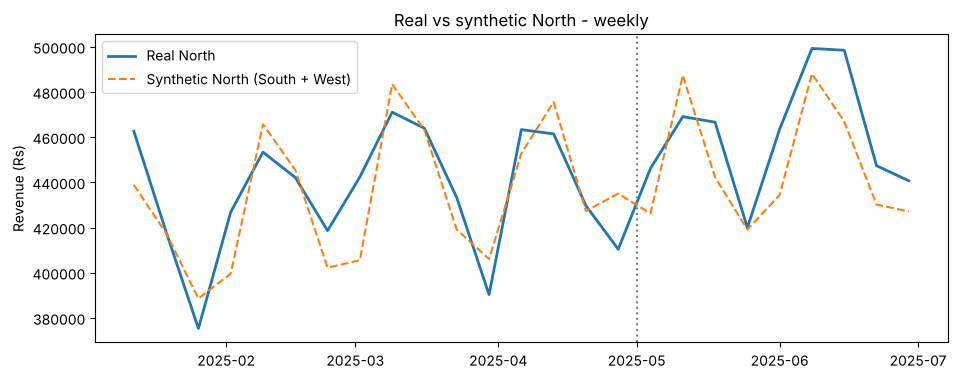

In [8]:
weights_weekly = fit_weights(weekly)
synth_weekly = build_synthetic(weekly, weights_weekly)
pre_w = synth_weekly[~synth_weekly["post"]]
rmse_w = np.sqrt((pre_w["gap"] ** 2).mean())

print("Donor weights (weekly data):")
print(weights_weekly.round(3))
print(f"Pre-period fit error: {rmse_w / pre_w['actual'].mean():.1%} of North's average weekly revenue")
plot_synthetic(synth_weekly, "Real vs synthetic North - weekly")

In [9]:
comparison = pd.DataFrame([daily_result, effect_summary(synth_weekly, "weekly")])
comparison

,data,avg extra revenue per period (Rs),lift (%),total extra revenue (Rs)
0,daily,2798,4.4,167866
1,weekly,14387,3.2,129486


## Part 6 - Export for MSPE validation (Member 3)

In [10]:
synth_daily.to_csv("synthetic_control_daily.csv")
synth_weekly.to_csv("synthetic_control_weekly.csv")
print("Saved synthetic_control_daily.csv and synthetic_control_weekly.csv")

Saved synthetic_control_daily.csv and synthetic_control_weekly.csv


## Findings
- **Synthetic North = about 52% South + 48% West** (daily data). On weekly data the mix is about 47% / 53%, so roughly an even blend either way.
- **Pre-period fit:** synthetic North tracks real North within about 10% on a typical day and about 4% on a typical week. Weekly is the more reliable fit.
- **Effect of the price rise:** after 1 May, real North earns about **3-4% more** than synthetic North, roughly **Rs 1.3-1.7 lakh extra over the 60 days** depending on daily vs weekly data.
- North's price rose about 7% while units sold stayed flat, which is consistent with a revenue gain.
- **Limitation:** only 2 donor regions, so the synthetic blend has little to choose from. Member 3's MSPE check and placebo tests next week will show how much to trust this number.